   # Perspective projection
   ### A 3D point (X, Y, Z) projects to x = f·X/Z, y = f·Y/Z on the image plane.
   A camera has f = 50 mm. A point is at (xo, yo, zo) = (1 m, 0.5 m, 10 m).
   xi = 50 mm × 1 / 10 = 5.0 mm, yi = 50 mm × 0.5 / 10 = 2.5 mm from the image centre.
   If each pixel is 5 μm wide, that is 5 mm / 0.005 mm = 1000 px right and 500 px up from the
   centre.

In [4]:
import numpy as np
f_mm =  50.0
pixel_mm = 0.005

def project(P, f=f_mm):
    X,Y,Z = P
    return f*X/Z, f*Y/Z
x_mm, y_mm = project((1.0, 0.5, 10.0))
print(x_mm, y_mm)
print(x_mm/pixel_mm, y_mm/pixel_mm)

5.0 2.5
1000.0 500.0


### Worked example 2 · How tall is a pedestrian in the image, and how far away?
An automotive camera has f = 6 mm and 3 μm pixels. A 1.75 m pedestrian stands 20 m away.
Height on the sensor: hi = f · H / z = 6 mm × 1.75 / 20 = 0.525 mm → 0.525 / 0.003 = 175 px.
At 40 m the same person is only 88 px tall; at 80 m, 44 px.

In [6]:
import numpy as np
import matplotlib.pyplot as plt

f_mm = 60
pixel_mm = 0.003
H_m = 1.75

def height_px(z_m, H=H_m, f=f_mm, p=pixel_mm):
    h_mm = f*H/z_m
    return h_mm/p

def distance_m(h_px, H=H_m, f=f_mm, p=pixel_mm):
    h_mm = h_px*p
    return f*H/h_mm

for z in [20, 40, 80]:
    print(f"{z:>3} m-> {height_px(z):6.1f} px")
print(f"100 px box -> {distance_m(100):.1f}m")

 20 m-> 1750.0 px
 40 m->  875.0 px
 80 m->  437.5 px
100 px box -> 350.0m


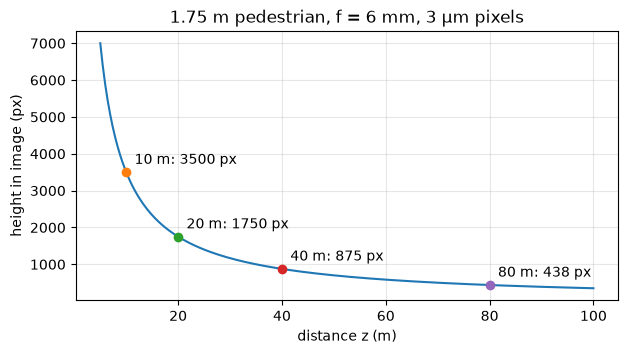

In [7]:
z = np.linspace(5, 100, 400)
plt.figure(figsize=(7, 3.5))
plt.plot(z, height_px(z))
for zz in [10, 20, 40, 80]:
    plt.plot(zz, height_px(zz), "o")
    plt.annotate(f"{zz} m: {height_px(zz):.0f} px", (zz, height_px(zz)),
                 xytext=(6, 6), textcoords="offset points")
plt.xlabel("distance z (m)")
plt.ylabel("height in image (px)")
plt.title("1.75 m pedestrian, f = 6 mm, 3 µm pixels")
plt.grid(alpha=0.3)
plt.show()

### Worked example 3 · Vanishing points of lane lines
Focal length in pixels f = 1000 px (image centre at (0, 0)).
Lanes straight ahead, l = (0, 0, 1): vanishing point (0, 0), the image centre.
A road turning right, l = (1, 0, 2): (1000 × 1/2, 0) = (500, 0) px, to the right of centre on the
horizon.
A road turning left, l = (−1, 0, 2): (−500, 0) px.

In [11]:
import numpy as np
import matplotlib.pyplot as plt

f_px = 1000.0

def vanishing_point(l, f=f_px):
    lx, ly, lz = l
    if np.isclose(lz, 0):
        return None
    return f*lx/lz, f*ly/lz

for name, l in[("straight",(0,0,1)), ("turning right",(1,0,2)), ("turning left", (-1,0,2)), ("parallel to image", (1,0,0))]:
    print(f"{name:18s} l={l} ->VP = {vanishing_point(l)}")

straight           l=(0, 0, 1) ->VP = (0.0, 0.0)
turning right      l=(1, 0, 2) ->VP = (500.0, 0.0)
turning left       l=(-1, 0, 2) ->VP = (-500.0, 0.0)
parallel to image  l=(1, 0, 0) ->VP = None


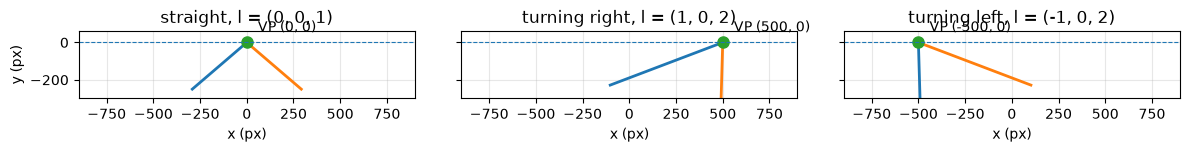

In [12]:
def project(P, f=f_px):
    P = np.asarray(P, dtype=float)
    return f * P[..., 0] / P[..., 2], f * P[..., 1] / P[..., 2]

cam_h = 1.5                      # camera height above the road (m); road at y = -1.5
half_w = 1.75                    # half lane width (m)
t = np.linspace(2, 400, 300)     # distance along the lane (m)

fig, axs = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, (name, l) in zip(axs, [("straight", (0, 0, 1)), ("turning right", (1, 0, 2)),
                               ("turning left", (-1, 0, 2))]):
    d = np.array(l, float); d /= np.linalg.norm(d)   # unit direction of the lane
    side = np.array([d[2], 0, -d[0]])                # horizontal direction across the lane
    for s in (-1, 1):                                # left and right lane edge
        start = np.array([0, -cam_h, 4.0]) + s * half_w * side
        pts = start + t[:, None] * d                 # 3D points along the edge
        x, y = project(pts)
        ax.plot(x, y, lw=2)
    vx, vy = vanishing_point(l)
    ax.plot(vx, vy, "o", ms=8)
    ax.annotate(f"VP ({vx:.0f}, {vy:.0f})", (vx, vy), xytext=(8, 8), textcoords="offset points")
    ax.axhline(0, ls="--", lw=0.8)                   # horizon line
    ax.set_title(f"{name}, l = {l}")
    ax.set_xlim(-900, 900); ax.set_ylim(-300, 60)
    ax.set_xlabel("x (px)"); ax.grid(alpha=0.3); ax.set_aspect("equal")
axs[0].set_ylabel("y (px)")
plt.tight_layout()
plt.show()